In [1]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

from src.modelo import riesgo_empirico
from src.optimizacion import ajustar_theta
from src.modelo import riesgo_empirico, p_theta
from src.simulacion import generar_datos

In [2]:
#1a

x = np.array([-2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2])
y = np.array([0, 0, 0, 1, 0, 1, 1, 1, 1])

theta0_vals = np.linspace(-4, 4, 100)
theta1_vals = np.linspace(-1, 6, 100)

matriz_riesgo = []

for t1 in theta1_vals:
    fila = []
    for t0 in theta0_vals:
        theta = (t0, t1)
        riesgo = riesgo_empirico(theta, x, y)
        fila.append(riesgo)
    matriz_riesgo.append(fila)

matriz_riesgo = np.array(matriz_riesgo)

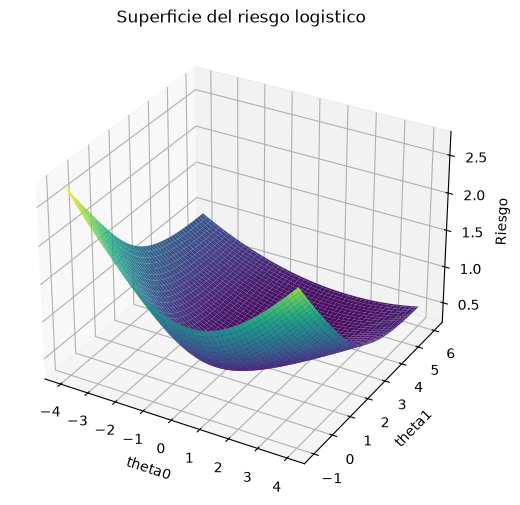

In [3]:
#b

theta0_vals_malla = []
theta1_vals_malla = []

for t1 in theta1_vals:
    fila_theta0 = []
    fila_theta1 = []
    for t0 in theta0_vals:
        fila_theta0.append(t0)
        fila_theta1.append(t1)
    theta0_vals_malla.append(fila_theta0)
    theta1_vals_malla.append(fila_theta1)

theta0_vals_malla = np.array(theta0_vals_malla)
theta1_vals_malla = np.array(theta1_vals_malla)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(theta0_vals_malla, theta1_vals_malla, matriz_riesgo, cmap="viridis")
ax.set_xlabel("theta0")
ax.set_ylabel("theta1")
ax.set_zlabel("Riesgo")
ax.set_title("Superficie del riesgo logistico")
plt.savefig("../resultados/superficie_riesgo.png")
plt.show()

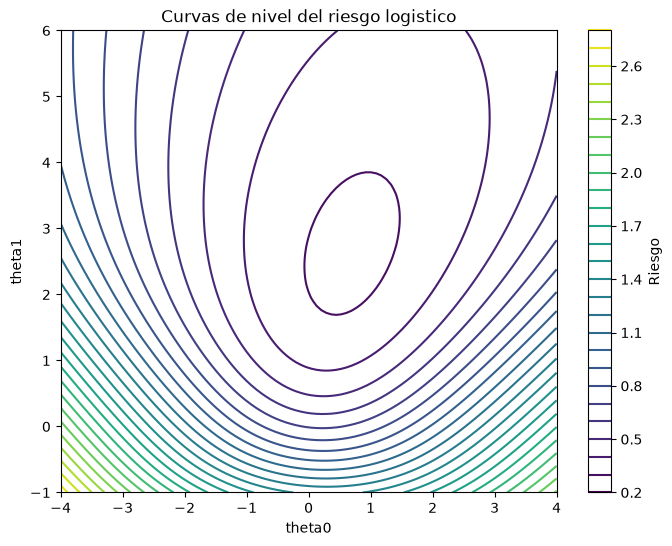

In [4]:
#b

plt.figure(figsize=(8, 6))
plt.contour(theta0_vals_malla, theta1_vals_malla, matriz_riesgo, levels=30, cmap="viridis")
plt.colorbar(label="Riesgo")
plt.xlabel("theta0")
plt.ylabel("theta1")
plt.title("Curvas de nivel del riesgo logistico")
plt.savefig("../resultados/curvas_nivel_riesgo.png")
plt.show()

In [5]:
#C

theta_hat, riesgo_hat, resultado_opt = ajustar_theta(x, y, theta_inicial=(0.0, 0.0))

print("theta_hat =", theta_hat)
print("riesgo en theta_hat =", riesgo_hat)

theta_hat = [0.65000893 2.5844874 ]
riesgo en theta_hat = 0.2784542389231837


In [6]:
#d
riesgo_en_theta_hat = riesgo_empirico(theta_hat, x, y)

theta_mas_theta0 = (theta_hat[0] + 0.1, theta_hat[1])
theta_mas_theta1 = (theta_hat[0], theta_hat[1] + 0.1)

riesgo_mas_theta0 = riesgo_empirico(theta_mas_theta0, x, y)
riesgo_mas_theta1 = riesgo_empirico(theta_mas_theta1, x, y)

print("riesgo en theta_hat =", riesgo_en_theta_hat)
print("riesgo en theta_hat + (0.1, 0) =", riesgo_mas_theta0)
print("riesgo en theta_hat + (0, 0.1) =", riesgo_mas_theta1)

print("es menor en la direccion theta0:", riesgo_en_theta_hat < riesgo_mas_theta0)
print("es menor en la direccion theta1:", riesgo_en_theta_hat < riesgo_mas_theta1)
#El resultado es true para ambas direcciones, lo que indica que theta_hat es un mínimo local del riesgo.    

riesgo en theta_hat = 0.2784542389231837
riesgo en theta_hat + (0.1, 0) = 0.2788813438435646
riesgo en theta_hat + (0, 0.1) = 0.27866459158721596
es menor en la direccion theta0: True
es menor en la direccion theta1: True


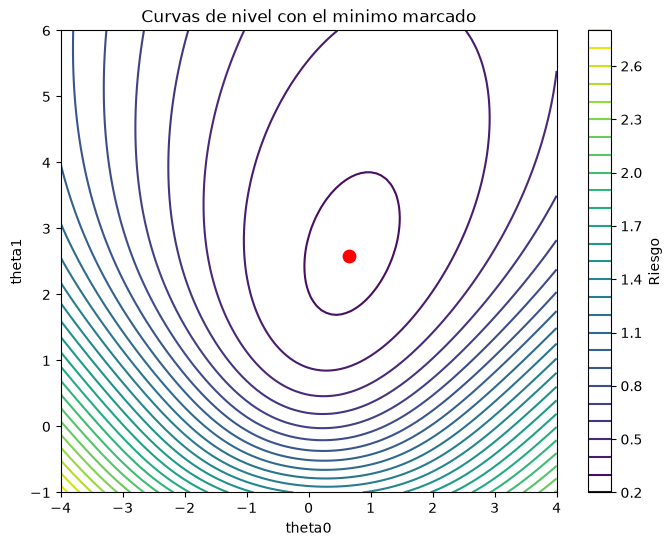

In [7]:
#d

plt.figure(figsize=(8, 6))
plt.contour(theta0_vals_malla, theta1_vals_malla, matriz_riesgo, levels=30, cmap="viridis")
plt.colorbar(label="Riesgo")
plt.scatter(theta_hat[0], theta_hat[1], color="red", s=80)
plt.xlabel("theta0")
plt.ylabel("theta1")
plt.title("Curvas de nivel con el minimo marcado")
plt.savefig("../resultados/curvas_nivel_con_minimo.png")
plt.show()

In [8]:
#2a
x = np.array([-2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2])
y_A = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1])
y_B = np.array([0, 0, 0, 1, 0, 1, 1, 1, 1])

theta_hat_A, riesgo_hat_A, resultado_A = ajustar_theta(x, y_A, theta_inicial=(0.0, 0.0))
theta_hat_B, riesgo_hat_B, resultado_B = ajustar_theta(x, y_B, theta_inicial=(0.0, 0.0))

print("Conjunto A: theta_hat =", theta_hat_A, " riesgo =", riesgo_hat_A)
print("Conjunto B: theta_hat =", theta_hat_B, " riesgo =", riesgo_hat_B)

Conjunto A: theta_hat = [ 9.41635756 42.00452063]  riesgo = 1.0074975641291329e-05
Conjunto B: theta_hat = [0.65000893 2.5844874 ]  riesgo = 0.2784542389231837


In [9]:
#b

norma_theta_A = np.sqrt(theta_hat_A[0]**2 + theta_hat_A[1]**2)
norma_theta_B = np.sqrt(theta_hat_B[0]**2 + theta_hat_B[1]**2)

print("conjunto   norma_theta      riesgo")
print("A         ", norma_theta_A, " ", riesgo_hat_A)
print("B         ", norma_theta_B, " ", riesgo_hat_B)

conjunto   norma_theta      riesgo
A          43.047038726357236   1.0074975641291329e-05
B          2.66497406053644   0.2784542389231837


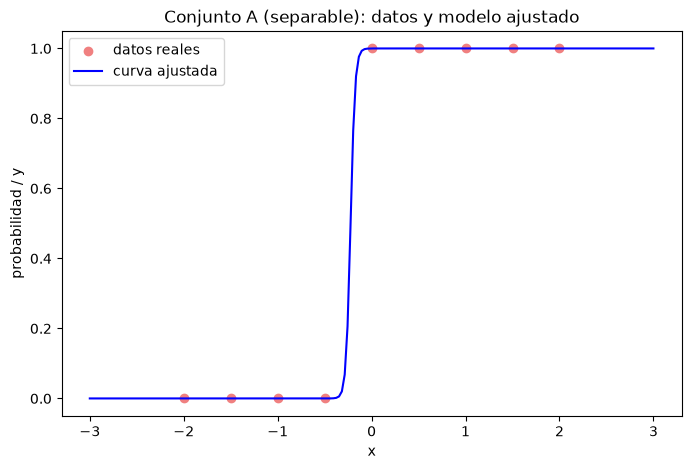

In [10]:
#C para conjunto A

x_curva = np.linspace(-3, 3, 200)
p_curva_A = p_theta(theta_hat_A, x_curva)

plt.figure(figsize=(8, 5))
plt.scatter(x, y_A, color="lightcoral", label="datos reales")
plt.plot(x_curva, p_curva_A, color="blue", label="curva ajustada")
plt.xlabel("x")
plt.ylabel("probabilidad / y")
plt.title("Conjunto A (separable): datos y modelo ajustado")
plt.legend()
plt.savefig("../resultados/ajuste_conjunto_A.png")
plt.show()

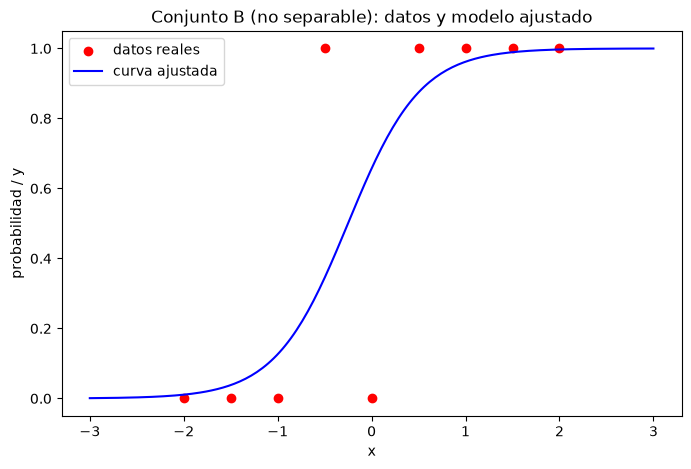

In [11]:
#C para conjunto B

p_curva_B = p_theta(theta_hat_B, x_curva)

plt.figure(figsize=(8, 5))
plt.scatter(x, y_B, color="red", label="datos reales")
plt.plot(x_curva, p_curva_B, color="blue", label="curva ajustada")
plt.xlabel("x")
plt.ylabel("probabilidad / y")
plt.title("Conjunto B (no separable): datos y modelo ajustado")
plt.legend()
plt.savefig("../resultados/ajuste_conjunto_B.png")
plt.show()

In [12]:
#d
theta_10, riesgo_10, resultado_10 = ajustar_theta(x, y_A, theta_inicial=(0.0, 0.0), maxiter=10)
theta_100, riesgo_100, resultado_100 = ajustar_theta(x, y_A, theta_inicial=(0.0, 0.0), maxiter=100)

norma_theta_10 = np.sqrt(theta_10[0]**2 + theta_10[1]**2)
norma_theta_100 = np.sqrt(theta_100[0]**2 + theta_100[1]**2)

print("maxiter=10:  norma_theta =", norma_theta_10, " riesgo =", riesgo_10)
print("maxiter=100: norma_theta =", norma_theta_100, " riesgo =", riesgo_100)

#Los datos son compatibles con la afirmación 2 donde la norma de theta aumenta con el número de iteraciones y el riesgo disminuye a 0, lo que indica que el modelo se ajusta mejor a los datos a medida que se permite más tiempo para la optimización. 

maxiter=10:  norma_theta = 16.02701103306834  riesgo = 0.005125896663231865
maxiter=100: norma_theta = 43.047038726357236  riesgo = 1.0074975641291329e-05


In [13]:
#3
theta_verdadero = np.array([-1, 2])
rng = np.random.default_rng(2026)

In [14]:
x_50, y_50 = generar_datos(50, rng, theta_verdadero=theta_verdadero)
theta_hat_50, riesgo_hat_50, resultado_50 = ajustar_theta(x_50, y_50, theta_inicial=(0.0, 0.0))

error_50 = np.sqrt((theta_hat_50[0] - theta_verdadero[0])**2 + (theta_hat_50[1] - theta_verdadero[1])**2)

print("theta_hat (n=50) =", theta_hat_50)
print("error (n=50) =", error_50)


x_200, y_200 = generar_datos(200, rng, theta_verdadero=theta_verdadero)
theta_hat_200, riesgo_hat_200, resultado_200 = ajustar_theta(x_200, y_200, theta_inicial=(0.0, 0.0))

error_200 = np.sqrt((theta_hat_200[0] - theta_verdadero[0])**2 + (theta_hat_200[1] - theta_verdadero[1])**2)

print("theta_hat (n=200) =", theta_hat_200)
print("error (n=200) =", error_200)


x_1000, y_1000 = generar_datos(1000, rng, theta_verdadero=theta_verdadero)
theta_hat_1000, riesgo_hat_1000, resultado_1000 = ajustar_theta(x_1000, y_1000, theta_inicial=(0.0, 0.0))

error_1000 = np.sqrt((theta_hat_1000[0] - theta_verdadero[0])**2 + (theta_hat_1000[1] - theta_verdadero[1])**2)

print("theta_hat (n=1000) =", theta_hat_1000)
print("error (n=1000) =", error_1000)

theta_hat (n=50) = [-1.61377749  2.68444765]
error (n=50) = 0.9193429094708561
theta_hat (n=200) = [-0.82299324  2.03820552]
error (n=200) = 0.1810830055510239
theta_hat (n=1000) = [-1.06598628  1.84996383]
error (n=1000) = 0.163905588425595


In [15]:
#d

print(f"{'n':<8}{'theta0_hat':<14}{'theta1_hat':<14}{'error':<10}")
print(f"{50:<8}{round(theta_hat_50[0], 3):<14}{round(theta_hat_50[1], 3):<14}{round(error_50, 3):<10}")
print(f"{200:<8}{round(theta_hat_200[0], 3):<14}{round(theta_hat_200[1], 3):<14}{round(error_200, 3):<10}")
print(f"{1000:<8}{round(theta_hat_1000[0], 3):<14}{round(theta_hat_1000[1], 3):<14}{round(error_1000, 3):<10}")

print()
print("el error mas pequeno lo tuvo n=1000:", error_1000 < error_200 and error_1000 < error_50)
print("es cierto que error(1000) < error(50):", error_1000 < error_50)

n       theta0_hat    theta1_hat    error     
50      -1.614        2.684         0.919     
200     -0.823        2.038         0.181     
1000    -1.066        1.85          0.164     

el error mas pequeno lo tuvo n=1000: True
es cierto que error(1000) < error(50): True


#4a

Partimos de la definición del modelo:

$$p_\theta(x) = \sigma(\theta_0 + \theta_1 x) = \frac{1}{1 + e^{-(\theta_0 + \theta_1 x)}}$$

Queremos ver para qué valores de $x$ se cumple $p_\theta(x) = 1/2$:

$$\frac{1}{1 + e^{-(\theta_0 + \theta_1 x)}} = \frac{1}{2}$$

$$1 + e^{-(\theta_0 + \theta_1 x)} = 2$$

$$e^{-(\theta_0 + \theta_1 x)} = 1$$

La función exponencial $e^t$ es igual a 1 únicamente cuando $t=0$, por lo tanto:

$$\theta_0 + \theta_1 x = 0$$

Como $\theta_1 \neq 0$, podemos despejar $x$:

$$x = -\frac{\theta_0}{\theta_1}$$

Esto demuestra que $p_\theta(x) = 1/2 \iff x = -\dfrac{\theta_0}{\theta_1}$.

theta0 = -2  x_frontera = 2.0  p en la frontera = 0.5
theta0 = 0  x_frontera = 0.0  p en la frontera = 0.5
theta0 = 2  x_frontera = -2.0  p en la frontera = 0.5


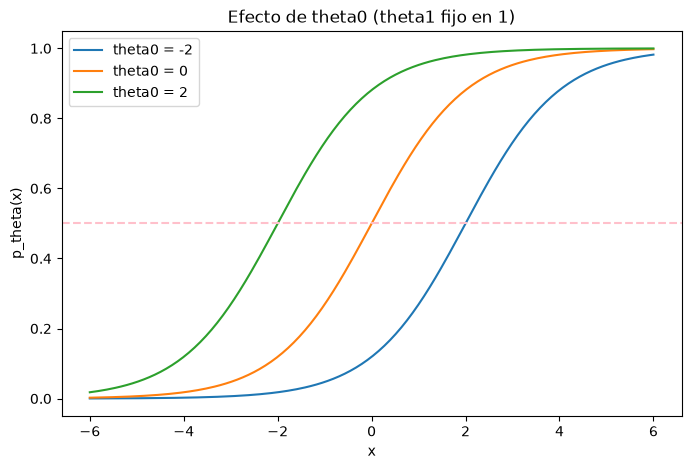

In [16]:
#4b

x_grafica = np.linspace(-6, 6, 200)
theta1_fijo = 1

valores_theta0 = [-2, 0, 2]

plt.figure(figsize=(8, 5))

for theta0 in valores_theta0:
    theta_actual = (theta0, theta1_fijo)
    p_valores = p_theta(theta_actual, x_grafica)
    plt.plot(x_grafica, p_valores, label="theta0 = " + str(theta0))

    x_frontera = -theta0 / theta1_fijo
    p_en_frontera = p_theta(theta_actual, x_frontera)
    print("theta0 =", theta0, " x_frontera =", x_frontera, " p en la frontera =", p_en_frontera)

plt.axhline(0.5, color="pink", linestyle="--")
plt.xlabel("x")
plt.ylabel("p_theta(x)")
plt.title("Efecto de theta0 (theta1 fijo en 1)")
plt.legend()
plt.savefig("../resultados/efecto_theta0.png")
plt.show()

#con theta1 es fijo la cruva se desplaza sin cambiar la forma, la forntera se mueve segun theta0, siempre se cumple p_theta(x*) = 0.5, confirmando el inciso a

theta1 = 1  p(1) - p(-1) = 0.4621171572600098
theta1 = 2  p(1) - p(-1) = 0.7615941559557647
theta1 = 5  p(1) - p(-1) = 0.9866142981514304


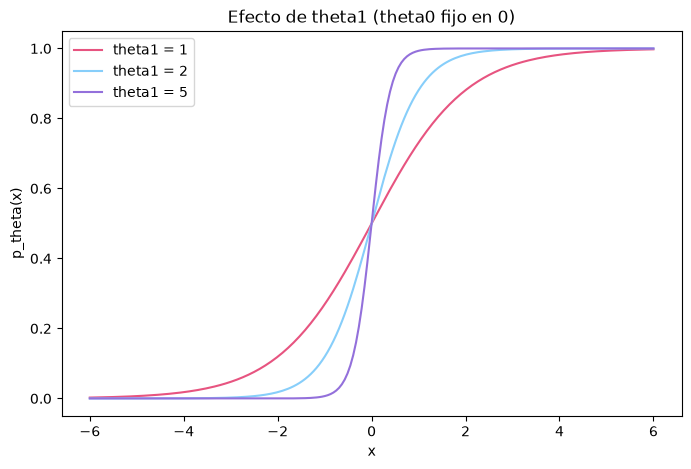

In [17]:
#c

theta0_fijo = 0
valores_theta1 = [1, 2, 5]
colores = ["#E75480", "#87CEFA", "#9370DB"]

plt.figure(figsize=(8, 5))

for theta1, color in zip(valores_theta1, colores):
    theta_actual = (theta0_fijo, theta1)
    p_valores = p_theta(theta_actual, x_grafica)
    plt.plot(x_grafica, p_valores, label="theta1 = " + str(theta1), color=color)

    p_en_1 = p_theta(theta_actual, 1)
    p_en_menos_1 = p_theta(theta_actual, -1)
    diferencia = p_en_1 - p_en_menos_1
    print("theta1 =", theta1, " p(1) - p(-1) =", diferencia)

plt.xlabel("x")
plt.ylabel("p_theta(x)")
plt.title("Efecto de theta1 (theta0 fijo en 0)")
plt.legend()
plt.savefig("../resultados/efecto_theta1.png")
plt.show()
#Para theta 1=5 la transicion es mas abrupta 

In [18]:
#5
x_5000, y_5000 = generar_datos(5000, rng, theta_verdadero=theta_verdadero)

In [19]:
# a

p_5000 = p_theta(theta_verdadero, x_5000)

likelihood = 1.0
log_likelihood = 0.0

for i in range(len(x_5000)):
    termino = (p_5000[i] ** y_5000[i]) * ((1 - p_5000[i]) ** (1 - y_5000[i]))
    likelihood = likelihood * termino
    log_likelihood = log_likelihood + np.log(termino)

print("L(theta*) =", likelihood)
print("log L(theta*) =", log_likelihood)

L(theta*) = 0.0
log L(theta*) = -1925.3310216201803


In [20]:
#b
print("L(theta*) es 0.0:", likelihood == 0.0)
print("log L(theta*) es finito:", np.isfinite(log_likelihood))
#si es finito 

L(theta*) es 0.0: True
log L(theta*) es finito: True


In [21]:
#c

riesgo_5000 = riesgo_empirico(theta_verdadero, x_5000, y_5000)

n = len(x_5000)
delta = abs(-log_likelihood - n * riesgo_5000)

print("riesgo empirico R_S(theta*) =", riesgo_5000)
print("n * R_S(theta*) =", n * riesgo_5000)
print("-log L(theta*) =", -log_likelihood)
print("delta =", delta)
print("delta < 1e-8:", delta < 1e-8)

riesgo empirico R_S(theta*) = 0.38506620432403527
n * R_S(theta*) = 1925.3310216201764
-log L(theta*) = 1925.3310216201803
delta = 3.865352482534945e-12
delta < 1e-8: True
